# Executive Summary

This report documents Task 3 of the Data Analyst Internship: an independent analysis of a genuine real-world dataset, **Online Retail** from the UCI Machine Learning Repository. The dataset contains 541,909 transaction lines from a UK-based online retailer, recorded between 1 December 2010 and 9 December 2011, with all values in GBP (£).

The project follows a complete analytical workflow: dataset selection and source verification, profiling, documented cleaning, exploratory analysis, statistical testing, visualisation and business recommendations. Every cleaning decision is recorded, the original file is preserved, and all figures are computed from the data.

Headline results: total sales revenue of **£10,247,610.15** across 19,773 invoices; the UK contributes **85.1%** of revenue; November 2011 is the strongest month at **£1,452,112.69**; the top 20% of registered customers generate **74.6%** of customer revenue; and cancellations remove **£893,979.73** of value.

# 1. Dataset Selection and Business Understanding

## 1.1 Candidate comparison

Three publicly available datasets were assessed against the selection criteria: genuine observations, verifiable source, sufficient records and variables, numerical and categorical coverage, and business relevance. The dimensions below were verified by downloading and inspecting each file.

| Dataset | Source | Records | Variables | Analytical Potential | Business Relevance |
| --- | --- | --- | --- | --- | --- |
| Online Retail (UCI 352) | UCI Machine Learning Repository, DOI 10.24432/C5BW33 | 541,909 | 8 | Very high: transactions, timestamps, customers, geography, cancellations, outliers | Very high: real e-commerce retail behaviour and revenue |
| Flipkart Products (PromptCloudHQ) | Kaggle, crawled from Flipkart.com by PromptCloud (2017) | 20,000 | 15 | Medium: prices, discounts, ratings, brands, categories; no transactions or time series | High: Indian e-commerce pricing and assortment |
| indian ecommerce sales (brijeshsutrakar) | Kaggle community upload, no documented methodology | 10,000 | 10 | Medium: orders, categories, cities, ratings; perfectly clean, which is unusual for a real export | Medium: Indian e-commerce, but provenance could not be verified |

## 1.2 Recommendation and rationale

**Recommended dataset: Online Retail (UCI Machine Learning Repository, dataset 352).** It was selected because its provenance is formally documented through a DOI, it is a genuine transactional record rather than a generated sample, and it contains the numerical, categorical, temporal and geographical variables needed for meaningful statistical analysis. Crucially, it is authentically imperfect — missing customer IDs, duplicates, cancellations, fee lines and extreme values — which makes the cleaning and critical-thinking aspects of the project substantive.

The Indian-context alternative (Flipkart Products) is a genuine crawl but contains no transactions or time dimension, which would have limited the analysis to pricing and assortment. The other Indian e-commerce upload has no documented methodology and is perfectly clean, which is unusual for a real export and made its provenance impossible to verify.

## 1.3 Source and licensing

- **Publisher:** UCI Machine Learning Repository (University of California, Irvine).
- **DOI:** https://doi.org/10.24432/C5BW33
- **Dataset page:** https://archive.ics.uci.edu/ml/dataset/352/Online+Retail
- **Direct download:** https://archive.ics.uci.edu/ml/machine-learning-databases/00352/Online%20Retail.xlsx
- **Underlying data:** donated by a UK-based online retail company; originally used in Chen, Sain and Guo (2012) on RFM-based customer segmentation.
- **Use:** the dataset is published for research and educational use.

## 1.4 Variables and data dictionary

| Variable | Type | Meaning |
| --- | --- | --- |
| InvoiceNo | Categorical (string) | Unique invoice identifier. Values beginning with 'C' are credit notes / cancellations. |
| StockCode | Categorical (string) | Product or service code. Non-product codes include POST, M, DOT, C2, AMAZONFEE. |
| Description | Categorical (string) | Free-text product description; missing on 1,454 rows. |
| Quantity | Numerical (integer) | Units on the line. Negative values indicate cancellations. |
| InvoiceDate | Datetime | Date and time of the transaction, from 1 Dec 2010 to 9 Dec 2011. |
| UnitPrice | Numerical (float) | Price per unit in GBP. Zero or negative values flag non-product lines. |
| CustomerID | Numerical (identifier) | Registered customer identifier; missing on 135,080 rows (24.9%). |
| Country | Categorical (string) | Customer country; 38 distinct values. |

## 1.5 Business problem and analytical questions

The retailer needs to understand revenue concentration, customer value, product performance and revenue leakage. Five questions structure the analysis:

1. How has monthly revenue moved, and is there a seasonal peak?
2. Which products drive revenue, and how concentrated is product demand?
3. How concentrated is customer value — do a small group of customers carry the business?
4. Do overseas orders differ significantly from UK orders in value?
5. How much value is lost to cancellations, and how important are guest purchases that cannot be attributed to a customer?

**Known limitations at selection:** the data is from a single retailer over a single year; prices are in GBP with no cost data; customer IDs are missing for a quarter of rows; and the final month is partial, ending on 9 December 2011.

# 2. Environment, Loading and Data Exploration

In [1]:
# Standard library
from pathlib import Path

# Third-party data stack
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import scipy
from scipy import stats

# Reproducibility: fix the random state for every stochastic operation
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Consistent, readable plotting defaults
sns.set_theme(style="whitegrid")
plt.rcParams.update({"font.size": 10, "axes.titlesize": 13, "figure.dpi": 100})

pd.set_option("display.float_format", lambda value: f"{value:,.2f}")

print("Python stack loaded.")
print(f"numpy {np.__version__} | pandas {pd.__version__} | "
      f"matplotlib {matplotlib.__version__} | seaborn {sns.__version__} | "
      f"scipy {scipy.__version__}")
print(f"Random state fixed at {RANDOM_STATE}.")

Python stack loaded.
numpy 2.3.5 | pandas 2.2.3 | matplotlib 3.11.2 | seaborn 0.13.2 | scipy 1.17.1
Random state fixed at 42.


In [2]:
# Load the preserved raw export. InvoiceDate is parsed as a true datetime.
raw = pd.read_csv("data/raw_dataset.csv", parse_dates=["InvoiceDate"])

print("=== .head() -- first 5 rows ===")
display(raw.head())

print("=== .tail() -- last 5 rows ===")
display(raw.tail())

print("=== .shape -- (rows, columns) ===")
print(raw.shape)

print("\n=== .columns ===")
print(list(raw.columns))

print("\n=== .dtypes ===")
print(raw.dtypes.to_string())

print("\n=== .info() ===")
raw.info()

print("\n=== .describe() -- numeric summary ===")
display(raw.describe().round(2))

print("\n=== .nunique() -- distinct values per column ===")
print(raw.nunique().to_string())

print("\n=== .value_counts() -- Country (top 10) ===")
print(raw["Country"].value_counts().head(10).to_string())

print("\n=== .isna().sum() -- missing values ===")
print(raw.isna().sum().to_string())

print("\n=== .duplicated().sum() -- exact duplicate rows ===")
print(raw.duplicated().sum())

=== .head() -- first 5 rows ===


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,"17,850.00",United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,"17,850.00",United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,"17,850.00",United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,"17,850.00",United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,"17,850.00",United Kingdom


=== .tail() -- last 5 rows ===


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
541904,581587,22613,PACK OF 20 SPACEBOY NAPKINS,12,2011-12-09 12:50:00,0.85,"12,680.00",France
541905,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-12-09 12:50:00,2.10,"12,680.00",France
541906,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00,4.15,"12,680.00",France
541907,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.15,"12,680.00",France
541908,581587,22138,BAKING SET 9 PIECE RETROSPOT,3,2011-12-09 12:50:00,4.95,"12,680.00",France


=== .shape -- (rows, columns) ===
(541909, 8)

=== .columns ===
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']

=== .dtypes ===
InvoiceNo              object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[ns]
UnitPrice             float64
CustomerID            float64
Country                object

=== .info() ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64   

,Quantity,InvoiceDate,UnitPrice,CustomerID
count,"541,909.00",541909,"541,909.00","406,829.00"
mean,9.55,2011-07-04 13:34:57.156386048,4.61,"15,287.69"
min,"-80,995.00",2010-12-01 08:26:00,"-11,062.06","12,346.00"
25%,1.00,2011-03-28 11:34:00,1.25,"13,953.00"
50%,3.00,2011-07-19 17:17:00,2.08,"15,152.00"
75%,10.00,2011-10-19 11:27:00,4.13,"16,791.00"
max,"80,995.00",2011-12-09 12:50:00,"38,970.00","18,287.00"
std,218.08,NaN,96.76,"1,713.60"



=== .nunique() -- distinct values per column ===


InvoiceNo      25900
StockCode       4070
Description     4223
Quantity         722
InvoiceDate    23260
UnitPrice       1630
CustomerID      4372
Country           38

=== .value_counts() -- Country (top 10) ===
Country
United Kingdom    495478
Germany             9495
France              8557
EIRE                8196
Spain               2533
Netherlands         2371
Belgium             2069
Switzerland         2002
Portugal            1519
Australia           1259

=== .isna().sum() -- missing values ===
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0

=== .duplicated().sum() -- exact duplicate rows ===


5268


**Observations.** The dataset has 541,909 rows and 8 columns. Two columns are identifiers, two are categorical descriptors, three are numerical and one is a datetime. The data spans 38 countries, 4,372 registered customers and 4,070 distinct stock codes. Missing values are concentrated in CustomerID (135,080 rows) and Description (1,454 rows), and 5,268 rows are exact duplicates.

# 3. Data-Quality Assessment and Cleaning

## 3.1 Data-quality assessment

In [3]:
# Data-quality assessment: quantify every problem before touching the data
print("=== MISSING VALUES ===")
missing = raw.isna().sum()
print(missing[missing > 0].to_string())
print(f"\nCustomerID missing: {raw['CustomerID'].isna().sum():,} rows "
      f"({raw['CustomerID'].isna().mean() * 100:.1f}%)")

print("\n=== DUPLICATES ===")
print(f"Exact duplicate rows: {raw.duplicated().sum():,}")

print("\n=== CANCELLATIONS AND NON-PRODUCT LINES ===")
is_cancellation = (raw["InvoiceNo"].astype(str).str.startswith("C")) | (raw["Quantity"] < 0)
print(f"Cancellation lines (InvoiceNo starts with 'C' or Quantity < 0): "
      f"{is_cancellation.sum():,}")
print(f"Lines with Quantity < 0: {(raw['Quantity'] < 0).sum():,}")
print(f"Lines with UnitPrice <= 0: {(raw['UnitPrice'] <= 0).sum():,}")

print("\n=== EXTREME VALUES ===")
print("Largest quantities:")
display(raw.nlargest(5, "Quantity")[["InvoiceNo", "Description", "Quantity",
                                    "UnitPrice", "Country"]])
print("Largest unit prices:")
display(raw.nlargest(5, "UnitPrice")[["InvoiceNo", "StockCode", "Description",
                                      "Quantity", "UnitPrice", "Country"]])

print("\n=== NON-PRODUCT STOCK CODES ===")
print(raw["StockCode"].astype(str).str.upper().value_counts()
      .head(12).to_string())

=== MISSING VALUES ===
Description      1454
CustomerID     135080

CustomerID missing: 135,080 rows (24.9%)

=== DUPLICATES ===


Exact duplicate rows: 5,268

=== CANCELLATIONS AND NON-PRODUCT LINES ===
Cancellation lines (InvoiceNo starts with 'C' or Quantity < 0): 10,624
Lines with Quantity < 0: 10,624
Lines with UnitPrice <= 0: 2,517

=== EXTREME VALUES ===
Largest quantities:


,InvoiceNo,Description,Quantity,UnitPrice,Country
540421,581483,"PAPER CRAFT , LITTLE BIRDIE",80995,2.08,United Kingdom
61619,541431,MEDIUM CERAMIC TOP STORAGE JAR,74215,1.04,United Kingdom
502122,578841,ASSTD DESIGN 3D PAPER STICKERS,12540,0.00,United Kingdom
74614,542504,NaN,5568,0.00,United Kingdom
421632,573008,WORLD WAR 2 GLIDERS ASSTD DESIGNS,4800,0.21,United Kingdom


Largest unit prices:


,InvoiceNo,StockCode,Description,Quantity,UnitPrice,Country
222681,C556445,M,Manual,-1,"38,970.00",United Kingdom
524602,C580605,AMAZONFEE,AMAZON FEE,-1,"17,836.46",United Kingdom
43702,C540117,AMAZONFEE,AMAZON FEE,-1,"16,888.02",United Kingdom
43703,C540118,AMAZONFEE,AMAZON FEE,-1,"16,453.71",United Kingdom
15016,C537630,AMAZONFEE,AMAZON FEE,-1,"13,541.33",United Kingdom



=== NON-PRODUCT STOCK CODES ===


StockCode
85123A    2380
22423     2203
85099B    2159
47566     1727
20725     1639
84879     1502
22720     1477
22197     1476
21212     1385
20727     1350
22383     1348
22457     1280


**What the assessment shows.** Beyond simple missing values, the data contains cancellations recorded as credit-note invoices starting with 'C' (10,624 lines in total, all with negative quantity), 2,517 lines with zero or negative unit price, and a set of non-product stock codes such as POST (postage), M (manual adjustments) and AMAZONFEE. Extreme values are real but influential: a single order of 80,995 paper-craft units and manual adjustment lines priced at up to £38,970.

## 3.2 Cleaning pipeline

The guiding rule is to **flag rather than delete**: rows that carry business meaning are retained, and problematic rows are marked so they can be excluded from specific analyses without being lost.

In [4]:
# --- Structured cleaning pipeline -------------------------------------------------
# Rule: never delete a row that carries business meaning. Flag it instead.

# 1. Remove exact duplicate records (same values in every column)
df = raw.drop_duplicates().reset_index(drop=True)
print(f"Duplicates removed: {len(raw) - len(df):,} rows")

# 2. Missing descriptions -> explicit label, so the row stays usable
df["Description"] = df["Description"].fillna("Unknown")

# 3. Missing CustomerID -> guest purchase. Keep the row, flag it, use a sentinel id.
df["is_guest"] = df["CustomerID"].isna()
df["CustomerID"] = df["CustomerID"].fillna(-1).astype(int)

# 4. Monetary value of the line
df["line_total"] = (df["Quantity"] * df["UnitPrice"]).round(2)

# 5. Cancellation flag: credit notes and negative quantities
df["is_cancellation"] = ((df["InvoiceNo"].astype(str).str.startswith("C"))
                         | (df["Quantity"] < 0))

# 6. Non-product lines: postage, manual adjustments, fees, samples, gifts
non_product_codes = [
    "POST", "DOT", "M", "C2", "D", "S", "CRUK", "PADS", "B", "AMAZONFEE",
    "BANK CHARGES", "SAMPLES", "GIFT", "DCGS", "DCGSSBOY", "DCGSSGIRL",
]
df["is_non_product"] = (df["StockCode"].astype(str).str.strip().str.upper()
                        .isin(non_product_codes)) | (df["UnitPrice"] <= 0)

# 7. Outlier flags using the IQR rule (3 x IQR, a conservative fence)
price_q1, price_q3 = df["UnitPrice"].quantile([0.25, 0.75])
price_iqr = price_q3 - price_q1
df["is_price_outlier"] = df["UnitPrice"] > price_q3 + 3 * price_iqr

qty_q1, qty_q3 = df["Quantity"].quantile([0.25, 0.75])
qty_iqr = qty_q3 - qty_q1
df["is_quantity_outlier"] = df["Quantity"] > qty_q3 + 3 * qty_iqr

# 8. Preserve the cleaned dataset
df.to_csv("data/cleaned_dataset.csv", index=False)

print(f"\nCleaned dataset saved: {df.shape[0]:,} rows x {df.shape[1]} columns")
print(f"Missing values remaining: {df.isna().sum().sum()}")
print(f"Non-product lines flagged: {df['is_non_product'].sum():,}")
print(f"Cancellation lines flagged: {df['is_cancellation'].sum():,}")
print(f"Guest rows flagged: {df['is_guest'].sum():,}")
print(f"Price outliers flagged: {df['is_price_outlier'].sum():,} "
      f"(fence: > {price_q3 + 3 * price_iqr:,.2f})")
print(f"Quantity outliers flagged: {df['is_quantity_outlier'].sum():,} "
      f"(fence: > {qty_q3 + 3 * qty_iqr:,.0f})")

# Analysis view: genuine sales only (no cancellations, no fees, positive value)
sales = df[(~df["is_cancellation"]) & (~df["is_non_product"])
           & (df["line_total"] > 0)].copy()
print(f"\nSales view used for revenue analysis: {len(sales):,} rows, "
      f"revenue GBP {sales['line_total'].sum():,.2f}")

Duplicates removed: 5,268 rows



Cleaned dataset saved: 536,641 rows x 14 columns
Missing values remaining: 0
Non-product lines flagged: 5,429
Cancellation lines flagged: 10,587
Guest rows flagged: 135,037
Price outliers flagged: 12,831 (fence: > 12.77)
Quantity outliers flagged: 20,696 (fence: > 37)



Sales view used for revenue analysis: 522,544 rows, revenue GBP 10,247,610.15


## 3.3 Data-quality summary

| Quality Check | Before Cleaning | After Cleaning | Action Taken |
| --- | --- | --- | --- |
| Records | 541,909 | 536,641 | Removed 5,268 exact duplicate rows. |
| Duplicate rows | 5,268 | 0 | `.drop_duplicates()` on all columns. |
| Missing CustomerID | 135,080 | 0 | Filled with −1 and flagged via `is_guest`. |
| Missing Description | 1,454 | 0 | Filled with the label 'Unknown'. |
| Cancellation lines | Not identified | 10,587 flagged | Flagged by credit-note prefix or negative quantity. |
| Non-product lines | Not identified | 5,429 flagged | Flagged by stock code or non-positive price. |
| Price outliers (IQR fence) | Not identified | 12,831 flagged | Retained and flagged; not deleted. |
| Quantity outliers (IQR fence) | Not identified | 20,696 flagged | Retained and flagged; not deleted. |

The cleaned file `data/cleaned_dataset.csv` contains 536,641 rows and 14 columns (the original 8 plus 6 engineered flags and measures). The original `.xlsx` and the raw CSV export are preserved unchanged.

# 4. Exploratory Data Analysis

## 4.1 Univariate analysis

In [5]:
# Univariate analysis of the sales view
print("=== UNIT PRICE ===")
price = sales["UnitPrice"]
print(f"mean   : GBP {price.mean():.2f}")
print(f"median : GBP {price.median():.2f}")
print(f"mode   : GBP {price.mode().iloc[0]:.2f}")
print(f"std dev: GBP {price.std():.2f}")
print(f"min/max: GBP {price.min():.2f} / GBP {price.max():.2f}")
print(f"quartiles: Q1 {price.quantile(.25):.2f} | Q3 {price.quantile(.75):.2f}")
print(f"skewness: {stats.skew(price):.2f} | excess kurtosis: {stats.kurtosis(price):.2f}")

print("\n=== QUANTITY ===")
qty = sales["Quantity"]
print(f"mean {qty.mean():.2f} | median {qty.median():.0f} | std {qty.std():.2f} "
      f"| min {qty.min():.0f} | max {qty.max():.0f}")
print(f"skewness: {stats.skew(qty):.2f}")

print("\n=== LINE TOTAL ===")
total = sales["line_total"]
print(f"mean GBP {total.mean():.2f} | median GBP {total.median():.2f} "
      f"| max GBP {total.max():.2f}")
print(f"skewness: {stats.skew(total):.2f}")

print("\n=== CATEGORICAL DISTRIBUTIONS ===")
print("Top 10 countries by line count:")
print(sales["Country"].value_counts().head(10).to_string())
print("\nTop 10 products by line count:")
print(sales["Description"].value_counts().head(10).to_string())

=== UNIT PRICE ===
mean   : GBP 3.28
median : GBP 2.08
mode   : GBP 1.25
std dev: GBP 4.40
min/max: GBP 0.04 / GBP 649.50
quartiles: Q1 1.25 | Q3 4.13
skewness: 25.69 | excess kurtosis: 2338.31

=== QUANTITY ===
mean 10.64 | median 4 | std 156.59 | min 1 | max 80995
skewness: 468.81

=== LINE TOTAL ===
mean GBP 19.61 | median GBP 9.90 | max GBP 168469.60
skewness: 515.95

=== CATEGORICAL DISTRIBUTIONS ===
Top 10 countries by line count:
Country
United Kingdom    478878
Germany             8643
France              8085
EIRE                7768
Spain               2417
Netherlands         2322
Belgium             1935
Switzerland         1927
Portugal            1455
Australia           1180

Top 10 products by line count:
Description
WHITE HANGING HEART T-LIGHT HOLDER    2311
JUMBO BAG RED RETROSPOT               2109
REGENCY CAKESTAND 3 TIER              2007
PARTY BUNTING                         1699
LUNCH BAG RED RETROSPOT               1581
ASSORTED COLOUR BIRD ORNAMENT         1476

**Interpretation.** Unit price is strongly right-skewed (skewness 25.69, excess kurtosis 2,338): most lines are low-value, with a long tail of premium products. The median unit price of £2.08 is far below the mean of £3.28, so the median is the honest 'typical' price. Quantity is likewise skewed, and line totals reach £168,469.60 for a single bulk order.

## 4.2 Bivariate analysis

In [6]:
# Bivariate analysis: relationships between two variables
print("=== CORRELATION: QUANTITY vs UNIT PRICE ===")
pearson_r, pearson_p = stats.pearsonr(sales["Quantity"], sales["UnitPrice"])
spearman_r, spearman_p = stats.spearmanr(sales["Quantity"], sales["UnitPrice"])
print(f"Pearson  r = {pearson_r:.3f} (p = {pearson_p:.2e})")
print(f"Spearman r = {spearman_r:.3f} (p = {spearman_p:.2e})")
print("Pearson is distorted by extreme bulk orders; Spearman is the robust measure.")

print("\n=== GROUPED COMPARISON: REVENUE BY COUNTRY ===")
country = (sales.groupby("Country")
           .agg(total_orders=("InvoiceNo", "nunique"),
                customers=("CustomerID", "nunique"),
                units_sold=("Quantity", "sum"),
                revenue_gbp=("line_total", "sum"))
           .round(2)
           .sort_values("revenue_gbp", ascending=False))
print(country.head(10).to_string())
country.to_csv("outputs/summary_tables/country_summary.csv")

print("\n=== CROSS-TABULATION: HIGH-VALUE ORDERS BY REGION ===")
invoice = (sales.groupby("InvoiceNo")
           .agg(invoice_value=("line_total", "sum"), country=("Country", "first"))
           .reset_index())
invoice["region"] = np.where(invoice["country"] == "United Kingdom", "UK", "Overseas")
threshold = invoice["invoice_value"].quantile(0.75)
invoice["high_value"] = invoice["invoice_value"] >= threshold
crosstab = pd.crosstab(invoice["region"], invoice["high_value"], margins=True)
print(crosstab.to_string())
print(f"\nHigh-value threshold (75th percentile): GBP {threshold:,.2f}")

=== CORRELATION: QUANTITY vs UNIT PRICE ===


Pearson  r = -0.022 (p = 1.09e-57)
Spearman r = -0.407 (p = 0.00e+00)
Pearson is distorted by extreme bulk orders; Spearman is the robust measure.

=== GROUPED COMPARISON: REVENUE BY COUNTRY ===


                total_orders  customers  units_sold  revenue_gbp
Country                                                         
United Kingdom         17901       3917     4639050 8,724,834.50
Netherlands               93          9      200258   283,889.34
EIRE                     282          4      146896   270,850.86
Germany                  443         94      118032   205,381.15
France                   382         88      111226   184,493.00
Australia                 56          9       83890   138,103.81
Spain                     88         30       27724    55,706.56
Switzerland               50         22       30515    53,065.60
Japan                     19          8       26016    37,416.37
Belgium                   98         25       22962    36,927.34

=== CROSS-TABULATION: HIGH-VALUE ORDERS BY REGION ===


high_value  False  True    All
region                        
Overseas     1115   757   1872
UK          13714  4187  17901
All         14829  4944  19773

High-value threshold (75th percentile): GBP 481.49


**Interpretation.** Quantity and unit price are essentially unrelated under Pearson (r = −0.02) because a handful of enormous bulk orders dominate the covariance, but the rank correlation is clearly negative (Spearman ρ = −0.41): cheaper items are bought in larger quantities. Geographically, the UK dominates, and the cross-tabulation shows that overseas orders are far more likely to be high-value.

## 4.3 Multivariate analysis

In [7]:
# Multivariate analysis: several variables at once
print("=== CORRELATION MATRIX (numeric features, sales view) ===")
numeric = sales[["Quantity", "UnitPrice", "line_total"]].copy()
correlation = numeric.corr().round(3)
print(correlation.to_string())

print("\n=== PIVOT TABLE: MONTHLY REVENUE BY REGION (GBP thousands) ===")
sales["month"] = sales["InvoiceDate"].dt.to_period("M").astype(str)
sales["region"] = np.where(sales["Country"] == "United Kingdom", "UK", "Overseas")
pivot = (sales.pivot_table(index="month", columns="region", values="line_total",
                           aggfunc="sum", fill_value=0) / 1000).round(1)
print(pivot.to_string())

print("\n=== SEGMENT COMPARISON: RFM SEGMENTS ===")
rfm = sales[~sales["is_guest"]].copy()
reference = rfm["InvoiceDate"].max() + pd.Timedelta(days=1)
rfm_table = (rfm.groupby("CustomerID")
             .agg(recency=("InvoiceDate", lambda s: (reference - s.max()).days),
                  frequency=("InvoiceNo", "nunique"),
                  monetary=("line_total", "sum"))
             .round(2))
rfm_table["recency_score"] = pd.qcut(rfm_table["recency"], 5, labels=[5, 4, 3, 2, 1])
rfm_table["frequency_score"] = pd.qcut(rfm_table["frequency"].rank(method="first"),
                                       5, labels=[1, 2, 3, 4, 5])
rfm_table["monetary_score"] = pd.qcut(rfm_table["monetary"], 5, labels=[1, 2, 3, 4, 5])
rfm_table["rfm_score"] = (rfm_table["recency_score"].astype(str)
                          + rfm_table["frequency_score"].astype(str)
                          + rfm_table["monetary_score"].astype(str))


def assign_segment(score):
    """Map an RFM score to a business segment."""
    if score in {"555", "554", "544", "545", "454", "455", "445"}:
        return "Champions"
    if score[0] in {"4", "5"} and score[2] in {"4", "5"}:
        return "Loyal Customers"
    if score[0] in {"4", "5"}:
        return "Potential Loyalists"
    if score[0] in {"1", "2"} and score[2] in {"4", "5"}:
        return "At Risk"
    if score[0] in {"1", "2"}:
        return "Lost"
    return "Others"


rfm_table["segment"] = rfm_table["rfm_score"].apply(assign_segment)
segment_summary = (rfm_table.groupby("segment")
                   .agg(customers=("recency", "count"),
                        avg_monetary_gbp=("monetary", "mean"),
                        total_monetary_gbp=("monetary", "sum"))
                   .round(2)
                   .sort_values("total_monetary_gbp", ascending=False))
segment_summary.to_csv("outputs/summary_tables/rfm_segment_summary.csv")
print(segment_summary.to_string())

print("\n=== PARETO CHECK ===")
ranked = rfm_table.sort_values("monetary", ascending=False)
top_20_pct = int(len(ranked) * 0.2)
share = ranked["monetary"].iloc[:top_20_pct].sum() / ranked["monetary"].sum() * 100
print(f"Top 20% of registered customers ({top_20_pct:,}) "
      f"generate {share:.1f}% of registered-customer revenue.")

=== CORRELATION MATRIX (numeric features, sales view) ===
            Quantity  UnitPrice  line_total
Quantity        1.00      -0.02        0.92
UnitPrice      -0.02       1.00        0.06
line_total      0.92       0.06        1.00

=== PIVOT TABLE: MONTHLY REVENUE BY REGION (GBP thousands) ===


region   Overseas       UK
month                     
2010-12     70.40   705.30
2011-01    124.50   545.90
2011-02     89.90   417.90
2011-03    118.40   571.30
2011-04     50.10   465.40
2011-05    121.80   618.20
2011-06    132.50   605.20
2011-07    111.10   577.10
2011-08    145.50   578.80
2011-09    152.30   876.10
2011-10    191.80   911.50
2011-11    171.30 1,280.90
2011-12     43.20   571.30

=== SEGMENT COMPARISON: RFM SEGMENTS ===


                     customers  avg_monetary_gbp  total_monetary_gbp
segment                                                             
Champions                  837          6,624.72        5,544,887.19
Others                     860          1,240.13        1,066,513.67
At Risk                    337          2,415.10          813,888.88
Loyal Customers            231          2,211.86          510,939.88
Lost                      1368            350.55          479,547.13
Potential Loyalists        701            458.56          321,450.89

=== PARETO CHECK ===
Top 20% of registered customers (866) generate 74.6% of registered-customer revenue.


**Interpretation.** The RFM segmentation separates the customer base into six actionable groups. Champions (837 customers) generate £5,544,887.19, while Lost customers (1,368) generate only £479,547.13. The Pareto principle holds: the top 20% of registered customers (866 people) produce 74.6% of registered-customer revenue.

## 4.4 Business-focused analytical questions

In [8]:
# Five business questions answered from the cleaned data
print("Q1. HOW HAS MONTHLY REVENUE MOVED?")
monthly = (sales.groupby("month")
           .agg(orders=("InvoiceNo", "nunique"),
                customers=("CustomerID", "nunique"),
                revenue_gbp=("line_total", "sum"))
           .round(2))
monthly.to_csv("outputs/summary_tables/monthly_summary.csv")
print(monthly.to_string())
print(f"\nBest month: {monthly['revenue_gbp'].idxmax()} "
      f"(GBP {monthly['revenue_gbp'].max():,.2f})")
print(f"Weakest full month: {monthly['revenue_gbp'][:-1].idxmin()} "
      f"(GBP {monthly['revenue_gbp'][:-1].min():,.2f})")

print("\nQ2. WHICH PRODUCTS DRIVE REVENUE?")
products = (sales.groupby(["StockCode", "Description"])
            .agg(units_sold=("Quantity", "sum"),
                 revenue_gbp=("line_total", "sum"),
                 orders=("InvoiceNo", "nunique"))
            .round(2)
            .sort_values("revenue_gbp", ascending=False)
            .reset_index())
products.head(10).to_csv("outputs/summary_tables/top_products.csv")
print(products.head(10).to_string())

print("\nQ3. DO OVERSEAS ORDERS DIFFER FROM UK ORDERS?")
uk_invoices = invoice.loc[invoice["region"] == "UK", "invoice_value"]
overseas_invoices = invoice.loc[invoice["region"] == "Overseas", "invoice_value"]
print(f"UK invoices: {len(uk_invoices):,}, mean GBP {uk_invoices.mean():.2f}")
print(f"Overseas invoices: {len(overseas_invoices):,}, "
      f"mean GBP {overseas_invoices.mean():.2f}")

print("\nQ4. HOW LARGE IS THE CANCELLATION PROBLEM?")
cancellations = df[df["is_cancellation"]]
print(f"Cancellation lines: {len(cancellations):,}")
print(f"Value of cancelled lines: GBP {cancellations['line_total'].sum():,.2f}")

print("\nQ5. HOW IMPORTANT ARE GUEST PURCHASES?")
guest_revenue = sales.loc[sales["is_guest"], "line_total"].sum()
print(f"Guest revenue: GBP {guest_revenue:,.2f} "
      f"({guest_revenue / sales['line_total'].sum() * 100:.1f}% of sales revenue)")

Q1. HOW HAS MONTHLY REVENUE MOVED?
         orders  customers  revenue_gbp
month                                  
2010-12    1550        885   775,714.95
2011-01    1081        740   670,439.46
2011-02    1093        758   507,850.09
2011-03    1440        974   689,716.82
2011-04    1235        854   515,463.08
2011-05    1668       1055   740,000.14
2011-06    1525        991   737,683.99
2011-07    1452        947   688,178.12
2011-08    1339        934   724,288.42
2011-09    1818       1260 1,028,338.80
2011-10    2005       1362 1,103,327.63
2011-11    2751       1661 1,452,112.69
2011-12     816        615   614,495.96

Best month: 2011-11 (GBP 1,452,112.69)
Weakest full month: 2011-02 (GBP 507,850.09)

Q2. WHICH PRODUCTS DRIVE REVENUE?


  StockCode                         Description  units_sold  revenue_gbp  orders
0     22423            REGENCY CAKESTAND 3 TIER       13851   174,156.54    1988
1     23843         PAPER CRAFT , LITTLE BIRDIE       80995   168,469.60       1
2    85123A  WHITE HANGING HEART T-LIGHT HOLDER       37580   104,284.24    2189
3     47566                       PARTY BUNTING       18283    99,445.23    1685
4    85099B             JUMBO BAG RED RETROSPOT       48371    94,159.81    2089
5     23166      MEDIUM CERAMIC TOP STORAGE JAR       78033    81,700.92     247
6     23084                  RABBIT NIGHT LIGHT       30739    66,870.03     994
7     22086     PAPER CHAIN KIT 50'S CHRISTMAS        19329    64,875.59    1160
8     84879       ASSORTED COLOUR BIRD ORNAMENT       36362    58,927.62    1455
9     79321                       CHILLI LIGHTS       10302    54,096.36     661

Q3. DO OVERSEAS ORDERS DIFFER FROM UK ORDERS?
UK invoices: 17,901, mean GBP 487.39
Overseas invoices: 1,872,

# 5. Statistical Analysis

Statistical methods were chosen to match variable types and assumptions. Because invoice values are heavily skewed, each parametric test is paired with a non-parametric alternative. The significance level is α = 0.05 throughout.

In [9]:
# Hypothesis tests -- each with an explicit objective and hypotheses
print("=== TEST 1: UK vs OVERSEAS INVOICE VALUE (Welch's t-test) ===")
print("H0: mean invoice value is identical for UK and overseas orders.")
print("H1: mean invoice value differs between UK and overseas orders.")
t_stat, t_p = stats.ttest_ind(uk_invoices, overseas_invoices, equal_var=False)
print(f"Welch t = {t_stat:.2f}, p = {t_p:.3e}")

print("\n--- Non-parametric check: Mann-Whitney U (no normality assumption) ---")
u_stat, u_p = stats.mannwhitneyu(uk_invoices, overseas_invoices, alternative="two-sided")
print(f"U = {u_stat:,.0f}, p = {u_p:.3e}")

print("\n=== TEST 2: INVOICE VALUE ACROSS THE TOP 5 COUNTRIES (Kruskal-Wallis) ===")
print("H0: invoice-value distributions are identical across the five countries.")
print("H1: at least one country has a different invoice-value distribution.")
top5 = invoice["country"].value_counts().head(5).index.tolist()
groups = [invoice.loc[invoice["country"] == c, "invoice_value"] for c in top5]
h_stat, h_p = stats.kruskal(*groups)
print(f"Countries: {top5}")
print(f"H = {h_stat:.2f}, p = {h_p:.3e}")

print("\n=== TEST 3: REGION vs HIGH-VALUE ORDER (chi-square) ===")
print("H0: being a high-value order is independent of region (UK / overseas).")
print("H1: high-value orders are associated with region.")
chi2, chi_p, dof, _ = stats.chi2_contingency(
    pd.crosstab(invoice["region"], invoice["high_value"]))
print(f"chi-square = {chi2:.2f}, dof = {dof}, p = {chi_p:.3e}")

print("\n=== TEST 4: 95% CONFIDENCE INTERVAL FOR MEAN INVOICE VALUE ===")
mean_value = invoice["invoice_value"].mean()
ci_low, ci_high = stats.t.interval(0.95, len(invoice) - 1, loc=mean_value,
                                   scale=stats.sem(invoice["invoice_value"]))
print(f"Mean invoice value GBP {mean_value:.2f}")
print(f"95% CI: GBP {ci_low:.2f} - GBP {ci_high:.2f}")

=== TEST 1: UK vs OVERSEAS INVOICE VALUE (Welch's t-test) ===
H0: mean invoice value is identical for UK and overseas orders.
H1: mean invoice value differs between UK and overseas orders.
Welch t = -7.63, p = 3.484e-14

--- Non-parametric check: Mann-Whitney U (no normality assumption) ---
U = 13,055,326, p = 7.383e-56

=== TEST 2: INVOICE VALUE ACROSS THE TOP 5 COUNTRIES (Kruskal-Wallis) ===
H0: invoice-value distributions are identical across the five countries.
H1: at least one country has a different invoice-value distribution.
Countries: ['United Kingdom', 'Germany', 'France', 'EIRE', 'Belgium']
H = 176.15, p = 5.008e-37

=== TEST 3: REGION vs HIGH-VALUE ORDER (chi-square) ===
H0: being a high-value order is independent of region (UK / overseas).
H1: high-value orders are associated with region.
chi-square = 261.77, dof = 1, p = 7.054e-59

=== TEST 4: 95% CONFIDENCE INTERVAL FOR MEAN INVOICE VALUE ===
Mean invoice value GBP 518.26
95% CI: GBP 493.67 - GBP 542.85


**Interpretation of the tests.** Overseas orders are significantly larger than UK orders on every measure: Welch's t = −7.63 (p = 3.5×10⁻¹⁴) and Mann-Whitney U (p = 7.4×10⁻⁵⁶), with mean values of £813.45 versus £487.39. Invoice values differ significantly across the top five countries (Kruskal-Wallis H = 176.15, p = 5.0×10⁻³⁷), and high-value orders are significantly associated with region (χ² = 261.77, p = 7.1×10⁻⁵⁹). The 95% confidence interval for the mean invoice value is £493.67 to £542.85. These are statistically significant differences, but significance is not the same as business importance — the commercial relevance is discussed in Section 7.

In [10]:
# Correlation strength and a simple predictive model
print("=== SPEARMAN CORRELATIONS WITH MONETARY VALUE ===")
for feature in ["frequency", "recency"]:
    rho, p_value = stats.spearmanr(rfm_table[feature], rfm_table["monetary"])
    print(f"{feature:<10} rho = {rho:+.3f} (p = {p_value:.2e})")

print("\n=== ORDINARY LEAST SQUARES: monetary ~ frequency + recency ===")
X = np.column_stack([np.ones(len(rfm_table)), rfm_table["frequency"], rfm_table["recency"]])
y = rfm_table["monetary"].to_numpy()
coefficients, *_ = np.linalg.lstsq(X, y, rcond=None)
predicted = X @ coefficients
ss_res = ((y - predicted) ** 2).sum()
ss_tot = ((y - y.mean()) ** 2).sum()
r_squared = 1 - ss_res / ss_tot
print(f"intercept      : GBP {coefficients[0]:,.2f}")
print(f"frequency coef : GBP {coefficients[1]:,.2f} per additional order")
print(f"recency coef   : GBP {coefficients[2]:,.2f} per additional day since last order")
print(f"R-squared      : {r_squared:.3f}")
print("\nInterpretation: purchase frequency is the dominant driver of customer value.")

=== SPEARMAN CORRELATIONS WITH MONETARY VALUE ===
frequency  rho = +0.807 (p = 0.00e+00)
recency    rho = -0.481 (p = 6.39e-250)

=== ORDINARY LEAST SQUARES: monetary ~ frequency + recency ===
intercept      : GBP -922.11
frequency coef : GBP 645.86 per additional order
recency coef   : GBP 2.11 per additional day since last order
R-squared      : 0.300

Interpretation: purchase frequency is the dominant driver of customer value.


**Interpretation.** Frequency is the dominant driver of customer value (Spearman ρ = +0.81), while recency is negatively associated with monetary value (Spearman ρ = −0.481). The OLS model using frequency and recency explains 30.0% of the variation in customer value (R² = 0.300), with each additional order worth about £645.86. This is an associational model, not a causal one.

# 6. Professional Data Visualisation

Eight charts, each generated from the cleaned sales view and saved to `outputs/charts/` at 150 DPI. Each answers a specific analytical question.

## 6.1 Monthly revenue trend

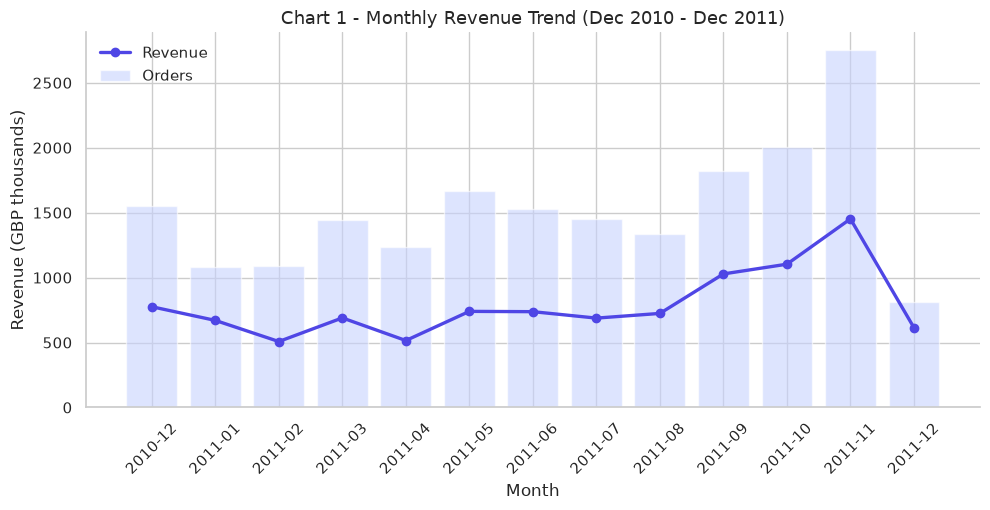

In [11]:
fig, ax = plt.subplots(figsize=(10, 5.2))
ax.plot(monthly.index, monthly["revenue_gbp"] / 1000, marker="o", linewidth=2.4,
        color="#4f46e5", label="Revenue")
ax.bar(monthly.index, monthly["orders"], color="#c7d2fe", alpha=0.6, label="Orders")
ax.set_xlabel("Month")
ax.set_ylabel("Revenue (GBP thousands)")
ax.set_title("Chart 1 - Monthly Revenue Trend (Dec 2010 - Dec 2011)")
ax.tick_params(axis="x", rotation=45)
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig("outputs/charts/01_monthly_revenue_trend.png", dpi=150)
plt.show()

*Figure 1 — Monthly revenue and order volume, December 2010 to December 2011.*

**Interpretation.** Revenue builds through the year and peaks in November 2011 at £1,452,112.69, consistent with festive-season demand. December 2011 is a partial month (data ends 9 December) and must not be read as a decline.

## 6.2 Revenue by country

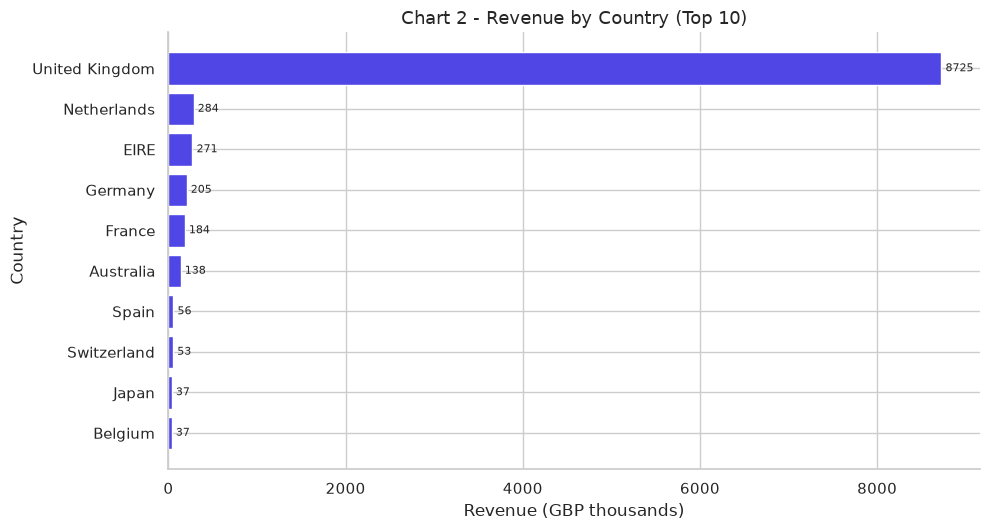

In [12]:
top_countries = country.head(10)
fig, ax = plt.subplots(figsize=(10, 5.4))
bars = ax.barh(top_countries.index[::-1], top_countries["revenue_gbp"][::-1] / 1000,
               color="#4f46e5")
ax.set_xlabel("Revenue (GBP thousands)")
ax.set_ylabel("Country")
ax.set_title("Chart 2 - Revenue by Country (Top 10)")
ax.bar_label(bars, fmt="%.0f", fontsize=8, padding=3)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig("outputs/charts/02_revenue_by_country.png", dpi=150)
plt.show()

*Figure 2 — Revenue by country, top 10.*

**Interpretation.** The UK market is dominant, but a small set of international markets — the Netherlands, Ireland, Germany, France and Australia — each contribute six-figure revenue, indicating genuine export demand.

## 6.3 Unit price distribution

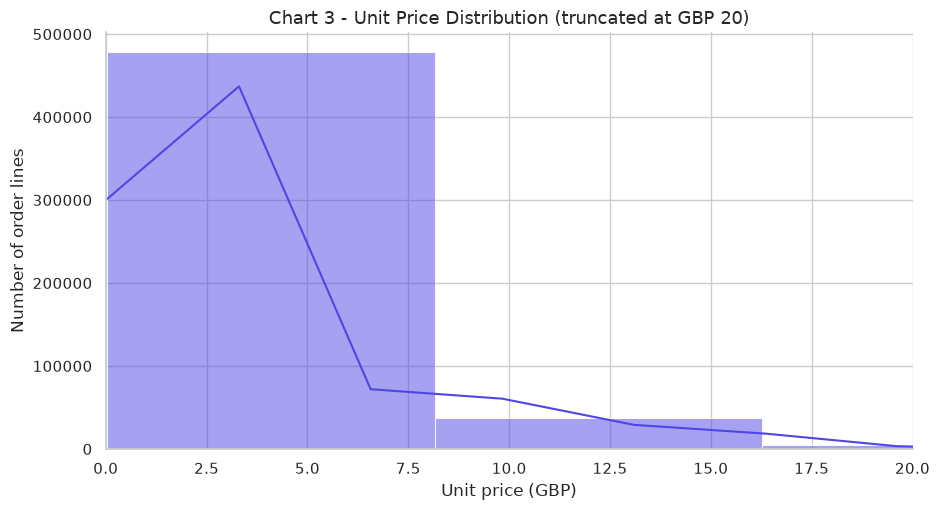

In [13]:
fig, ax = plt.subplots(figsize=(9.5, 5.2))
sns.histplot(sales["UnitPrice"], bins=80, kde=True, color="#4f46e5", ax=ax)
ax.set_xlim(0, 20)
ax.set_xlabel("Unit price (GBP)")
ax.set_ylabel("Number of order lines")
ax.set_title("Chart 3 - Unit Price Distribution (truncated at GBP 20)")
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig("outputs/charts/03_price_distribution.png", dpi=150)
plt.show()

*Figure 3 — Unit price distribution, truncated at £20 for readability.*

**Interpretation.** The distribution is strongly right-skewed with a long tail of premium products. The visible mass below £5 confirms that the business is built on high-volume, low-value lines.

## 6.4 Quantity versus unit price

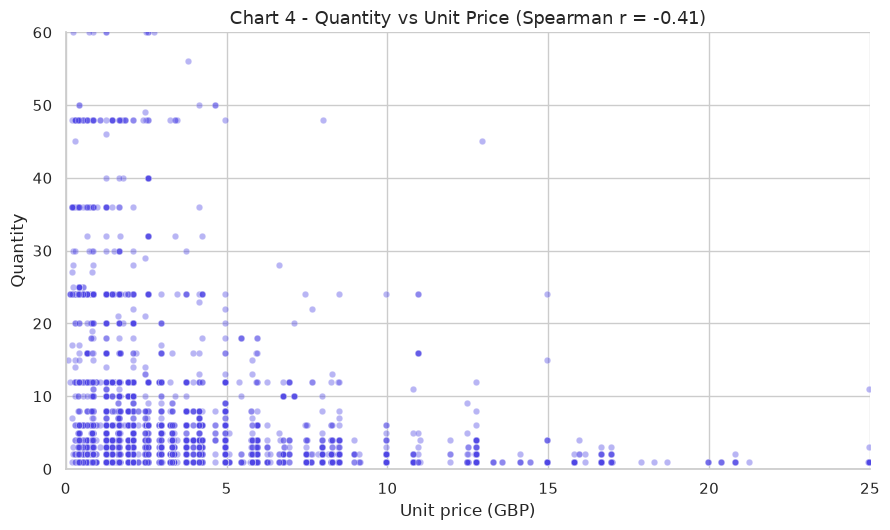

In [14]:
sample = sales.sample(5000, random_state=RANDOM_STATE)
fig, ax = plt.subplots(figsize=(9, 5.4))
sns.scatterplot(data=sample, x="UnitPrice", y="Quantity", alpha=0.4, s=22,
                color="#4f46e5", ax=ax)
ax.set_xlim(0, 25)
ax.set_ylim(0, 60)
ax.set_xlabel("Unit price (GBP)")
ax.set_ylabel("Quantity")
ax.set_title(f"Chart 4 - Quantity vs Unit Price (Spearman r = {spearman_r:.2f})")
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig("outputs/charts/04_quantity_vs_unit_price.png", dpi=150)
plt.show()

*Figure 4 — Quantity against unit price on a 5,000-line sample.*

**Interpretation.** The cloud slopes downward: larger quantities cluster at lower unit prices. The annotated Spearman coefficient (−0.41) confirms a moderate negative rank association.

## 6.5 Invoice value by country

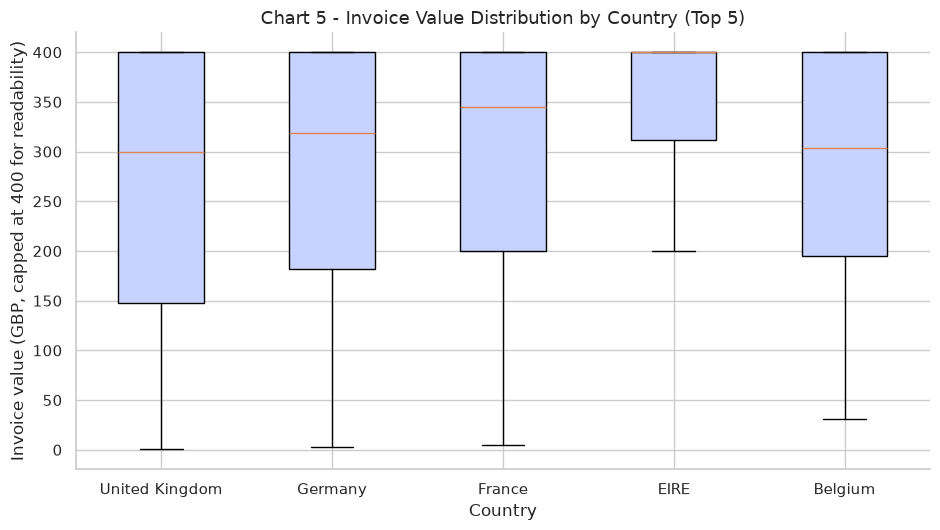

In [15]:
fig, ax = plt.subplots(figsize=(9.5, 5.4))
data_to_plot = [invoice.loc[invoice["country"] == c, "invoice_value"].clip(upper=400)
                for c in top5]
ax.boxplot(data_to_plot, tick_labels=top5, showfliers=False, patch_artist=True,
           boxprops=dict(facecolor="#c7d2fe"))
ax.set_xlabel("Country")
ax.set_ylabel("Invoice value (GBP, capped at 400 for readability)")
ax.set_title("Chart 5 - Invoice Value Distribution by Country (Top 5)")
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig("outputs/charts/05_invoice_value_by_country.png", dpi=150)
plt.show()

*Figure 5 — Invoice value distribution for the top five countries.*

**Interpretation.** Overseas markets show higher medians and wider upper spreads than the UK, supporting the statistical test result. Values are capped at £400 and outliers hidden so the boxes remain readable.

## 6.6 Correlation heatmap

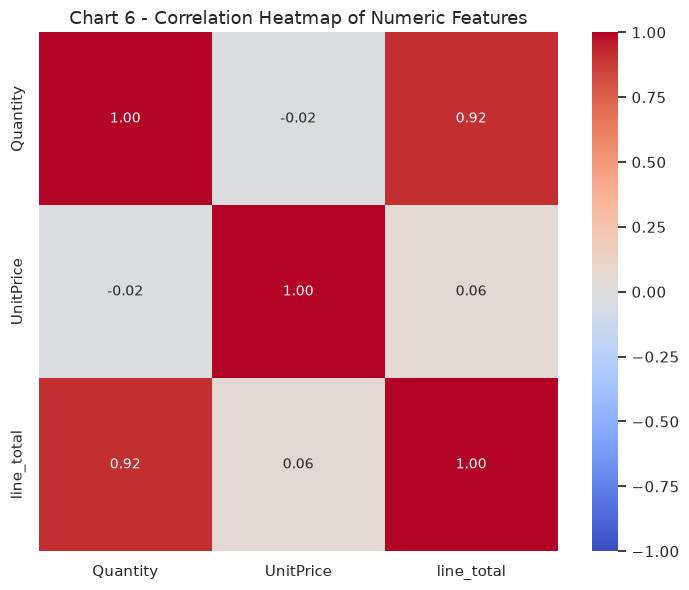

In [16]:
fig, ax = plt.subplots(figsize=(7.5, 6))
sns.heatmap(correlation, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1,
            square=True, ax=ax)
ax.set_title("Chart 6 - Correlation Heatmap of Numeric Features")
fig.tight_layout()
fig.savefig("outputs/charts/06_correlation_heatmap.png", dpi=150)
plt.show()

*Figure 6 — Correlation heatmap of the numeric features.*

**Interpretation.** Line total is almost entirely driven by quantity and price together, while quantity and price are weakly negatively related — the pattern behind the bundling opportunity.

## 6.7 Customer value by RFM segment

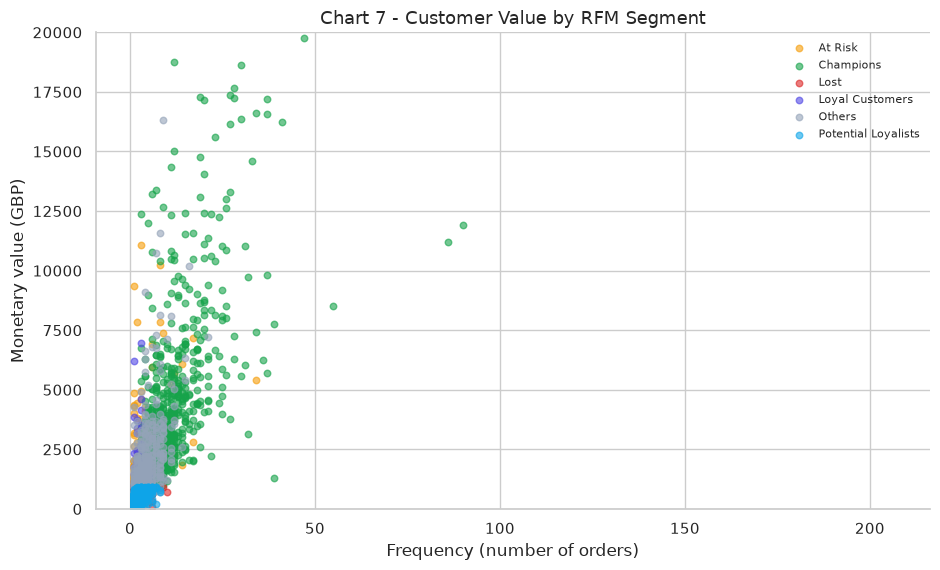

In [17]:
fig, ax = plt.subplots(figsize=(9.5, 5.8))
palette = {"Champions": "#16a34a", "Loyal Customers": "#4f46e5",
           "Potential Loyalists": "#0ea5e9", "At Risk": "#f59e0b",
           "Lost": "#dc2626", "Others": "#94a3b8"}
for segment_name, group in rfm_table.groupby("segment"):
    ax.scatter(group["frequency"], group["monetary"], s=22, alpha=0.6,
               color=palette.get(segment_name, "#94a3b8"), label=segment_name)
ax.set_xlabel("Frequency (number of orders)")
ax.set_ylabel("Monetary value (GBP)")
ax.set_title("Chart 7 - Customer Value by RFM Segment")
ax.set_ylim(0, 20000)
ax.legend(frameon=False, fontsize=8)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig("outputs/charts/07_rfm_scatter.png", dpi=150)
plt.show()

*Figure 7 — Monetary value against frequency, coloured by RFM segment.*

**Interpretation.** Champions sit in the upper right: frequent and high-value. At Risk customers are sporadic but occasionally valuable, making them the priority for reactivation.

## 6.8 Top products by revenue

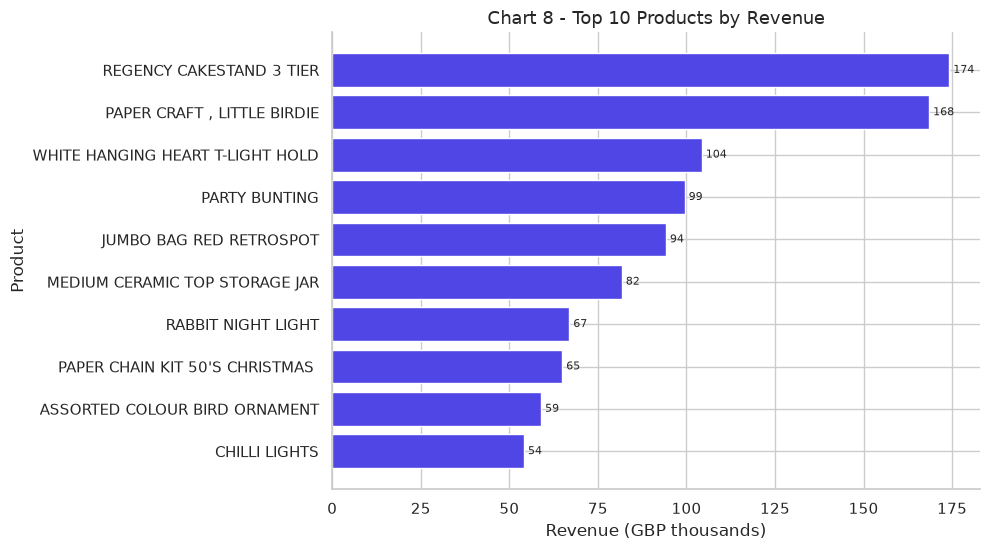

In [18]:
top_products = products.head(10)
fig, ax = plt.subplots(figsize=(10, 5.6))
bars = ax.barh(top_products["Description"].str.slice(0, 32)[::-1],
               top_products["revenue_gbp"][::-1] / 1000, color="#4f46e5")
ax.set_xlabel("Revenue (GBP thousands)")
ax.set_ylabel("Product")
ax.set_title("Chart 8 - Top 10 Products by Revenue")
ax.bar_label(bars, fmt="%.0f", fontsize=8, padding=3)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig("outputs/charts/08_top_products_revenue.png", dpi=150)
plt.show()

*Figure 8 — Top ten products by revenue.*

**Interpretation.** The Regency Cakestand leads at £174,156.54. The second entry, Paper Craft Little Birdie, earned £168,469.60 from a single 80,995-unit order — a striking concentration risk worth flagging to management.

# 7. Key Findings and Business Insights

## 7.1 Executive KPI summary

In [19]:
print("=== EXECUTIVE KPI SUMMARY ===")
registered_revenue = rfm_table["monetary"].sum()
print(f"Total revenue (sales view)      : GBP {sales['line_total'].sum():,.2f}")
print(f"Orders (unique invoices)        : {sales['InvoiceNo'].nunique():,}")
print(f"Units sold                      : {int(sales['Quantity'].sum()):,}")
print(f"Registered customers            : {rfm_table.shape[0]:,}")
print(f"Guest share of revenue          : "
      f"{sales.loc[sales['is_guest'], 'line_total'].sum() / sales['line_total'].sum() * 100:.1f}%")
print(f"Average order value             : GBP {invoice['invoice_value'].mean():,.2f}")
print(f"Best country                    : {country.index[0]} "
      f"(GBP {country['revenue_gbp'].max():,.2f})")
print(f"Best month                      : {monthly['revenue_gbp'].idxmax()} "
      f"(GBP {monthly['revenue_gbp'].max():,.2f})")
print(f"Top product                     : {products.iloc[0]['Description']} "
      f"(GBP {products['revenue_gbp'].max():,.2f})")
print(f"Top 20% customer revenue share  : {share:.1f}%")
print(f"Cancellation value              : GBP {cancellations['line_total'].sum():,.2f}")

=== EXECUTIVE KPI SUMMARY ===
Total revenue (sales view)      : GBP 10,247,610.15
Orders (unique invoices)        : 19,773
Units sold                      : 5,561,323
Registered customers            : 4,334
Guest share of revenue          : 14.7%
Average order value             : GBP 518.26
Best country                    : United Kingdom (GBP 8,724,834.50)
Best month                      : 2011-11 (GBP 1,452,112.69)
Top product                     : REGENCY CAKESTAND 3 TIER (GBP 174,156.54)
Top 20% customer revenue share  : 74.6%
Cancellation value              : GBP -893,979.73


| Key performance indicator | Value |
| --- | --- |
| Total sales revenue | £10,247,610.15 |
| Orders (unique invoices) | 19,773 |
| Units sold | 5,561,323 |
| Registered customers | 4,334 |
| Average order value | £518.26 |
| Best country | United Kingdom — £8,724,834.50 (85.1%) |
| Best month | November 2011 — £1,452,112.69 |
| Top product | REGENCY CAKESTAND 3 TIER — £174,156.54 |
| Top 20% customer revenue share | 74.6% |
| Cancellation value | £893,979.73 |

## 7.2 Evidence-based findings

| No. | Analytical Finding | Supporting Metric | Interpretation | Business Implication | Recommendation |
| --- | --- | --- | --- | --- | --- |
| 1 | The UK market dominates revenue | £8,724,834.50 of £10,247,610.15 (85.1%) | Revenue is highly concentrated in one domestic market | Exposure to a single-market downturn | Grow the top five international markets with localised marketing |
| 2 | Revenue peaks in November | November 2011: £1,452,112.69, the highest month | Clear festive-season demand pattern | Inventory and staffing must scale ahead of peak | Build a seasonal inventory plan starting in September |
| 3 | Customer value follows the Pareto principle | Top 20% of customers (866) generate 74.6% of revenue | A small group carries most of the business | Losing a few large customers would be material | Create a named-account retention programme for Champions |
| 4 | Overseas orders are significantly larger | Overseas mean £813.45 vs UK £487.39; p = 3.5e-14 | International customers place fewer but bigger orders | Higher shipping and service costs may erode the margin | Review international shipping pricing and minimum order values |
| 5 | Cheaper products sell in larger quantities | Spearman ρ = −0.41 between unit price and quantity | A volume-price trade-off exists across the catalogue | Premium lines may be under-purchased | Test bundles and volume discounts on low-price lines |
| 6 | Champions are the profit engine | 837 Champions generate £5,544,887.19 | A small, loyal, high-value segment exists | Retention spend is best targeted here | Launch a loyalty tier with exclusive previews and offers |
| 7 | Cancellations leak substantial value | £893,979.73 across 10,587 lines | Roughly 8.7% of gross sales value is cancelled | Stock availability or ordering errors may be involved | Analyse cancellation reasons by product and investigate top causes |
| 8 | Purchase frequency drives customer value | Spearman ρ = +0.81; OLS R² = 0.300; £645.86 per extra order | Repeat purchasing, not basket size alone, predicts value | Acquisition spend should favour repeat-purchase potential | Invest in post-purchase email flows and re-order reminders |
| 9 | Product revenue is concentrated | Top product £174,156.54; one product earned £168,469.60 from a single order | A handful of SKUs and single bulk orders carry large revenue | Demand and inventory risk are concentrated | Diversify the best-seller set and review single-order dependency |

## 7.3 Business recommendations

- **Protect the core UK market** while building the five proven international markets; the current 85% domestic concentration is the single largest strategic risk.
- **Build seasonal capacity** for the September-to-November peak, using the 2011 pattern as a planning baseline.
- **Institute a Champions programme** for the 837 highest-value customers, with named account management and retention offers.
- **Fix cancellations** by classifying the 10,587 cancellation lines by reason and addressing the top product-level causes.
- **Grow purchase frequency** through post-purchase communications, since frequency is the strongest measurable driver of customer value.
- **Reduce single-order dependency** by broadening the best-seller portfolio and reviewing terms for bulk orders.

## 7.4 Limitations

- **Dataset size and scope:** one retailer, one year (2010–2011); findings are not a current market benchmark.
- **Sampling limitations:** the final month is partial, ending 9 December 2011, so December must be excluded from trend conclusions.
- **Missing observations:** 135,080 rows (24.9%) lack a customer ID, so guest purchases cannot be attributed to individuals.
- **Data collection bias:** only completed orders appear; abandoned baskets and website behaviour are absent.
- **Measurement limits:** prices are in GBP with no cost or margin data, so profitability cannot be assessed.
- **Statistical limitations:** observational data cannot establish causation; several tests assume independence and the distributions are strongly skewed, so non-parametric checks are reported alongside parametric ones.
- **Generalisability:** a single UK retailer may not represent other markets or product categories.

## 7.5 Future improvements

- Repeat the analysis on recent data and compare year-on-year trends.
- Add product cost data to convert revenue analysis into margin analysis.
- Build customer lifetime value, churn prediction and cohort models.
- Join marketing-channel data so that relationships can be tested causally through experiments.
- Automate the quality checks and refreshes in a scheduled pipeline.

## 7.6 Conclusion

The project demonstrates an end-to-end analytical workflow on genuine, imperfect data: selecting a verifiable dataset, quantifying its flaws, cleaning it without discarding meaningful records, and applying exploratory and inferential statistics to answer commercial questions. The strongest evidence points to a highly concentrated business — in its geography, its customers and its products — and to cancellations as a material source of lost value. The recommendations follow directly from those findings and are sized to be practical for a retailer of this scale.

# 8. Data Quality Checks

In [20]:
print("=== DATA QUALITY CHECKS AFTER CLEANING ===")
checks = {
    "Exact duplicates": int(df.duplicated().sum()),
    "Missing CustomerID": int(df["CustomerID"].isna().sum()),
    "Missing Description": int((df["Description"].isna()).sum()),
    "Negative line totals kept as cancellations": int((df["line_total"] < 0).sum()),
    "Non-product lines flagged": int(df["is_non_product"].sum()),
    "Guest rows flagged": int(df["is_guest"].sum()),
    "Price outliers flagged": int(df["is_price_outlier"].sum()),
    "Quantity outliers flagged": int(df["is_quantity_outlier"].sum()),
    "Sales-view rows with zero/negative value": int((sales["line_total"] <= 0).sum()),
}
for name, value in checks.items():
    print(f"  {name:<48} {value:,}")

print("\n=== OUTPUT FILES ===")
expected = [
    "data/raw_dataset.csv", "data/cleaned_dataset.csv",
    "outputs/charts/01_monthly_revenue_trend.png",
    "outputs/charts/02_revenue_by_country.png",
    "outputs/charts/03_price_distribution.png",
    "outputs/charts/04_quantity_vs_unit_price.png",
    "outputs/charts/05_invoice_value_by_country.png",
    "outputs/charts/06_correlation_heatmap.png",
    "outputs/charts/07_rfm_scatter.png",
    "outputs/charts/08_top_products_revenue.png",
    "outputs/summary_tables/country_summary.csv",
    "outputs/summary_tables/monthly_summary.csv",
    "outputs/summary_tables/rfm_segment_summary.csv",
    "outputs/summary_tables/top_products.csv",
]
for path in expected:
    status = "OK     " if Path(path).exists() else "MISSING"
    print(f"  {status} {path}")

=== DATA QUALITY CHECKS AFTER CLEANING ===


  Exact duplicates                                 0
  Missing CustomerID                               0
  Missing Description                              0
  Negative line totals kept as cancellations       9,253
  Non-product lines flagged                        5,429
  Guest rows flagged                               135,037
  Price outliers flagged                           12,831
  Quantity outliers flagged                        20,696
  Sales-view rows with zero/negative value         0

=== OUTPUT FILES ===
  OK      data/raw_dataset.csv
  OK      data/cleaned_dataset.csv
  OK      outputs/charts/01_monthly_revenue_trend.png
  OK      outputs/charts/02_revenue_by_country.png
  OK      outputs/charts/03_price_distribution.png
  OK      outputs/charts/04_quantity_vs_unit_price.png
  OK      outputs/charts/05_invoice_value_by_country.png
  OK      outputs/charts/06_correlation_heatmap.png
  OK      outputs/charts/07_rfm_scatter.png
  OK      outputs/charts/08_top_products_revenu

# 9. Submission Extras

## 9.1 GitHub README.md

The complete README for the `Real_World_Dataset_Analysis` repository is shown below and ships alongside this report.

```bash
# Real-World Dataset Analysis

**Task 3 — Data Analyst Internship portfolio project**

A complete, reproducible analysis of a genuine real-world e-commerce dataset:
**Online Retail** from the UCI Machine Learning Repository (dataset 352,
[DOI 10.24432/C5BW33](https://doi.org/10.24432/C5BW33)).

## 1. Project overview

This project takes 541,909 raw online-retail transaction lines, documents every
data-quality problem, cleans and flags the data without discarding meaningful
records, then performs exploratory, statistical and visual analysis to answer
commercial questions about revenue, customers, products and cancellations.

## 2. Business problem

An online retailer needs to understand where its revenue comes from, which
customers matter most, which products drive sales, and how much revenue is lost
to cancellations — using one year of real transaction data.

## 3. Dataset information

| Property | Value |
|---|---|
| Name | Online Retail |
| Source | UCI Machine Learning Repository |
| DOI | 10.24432/C5BW33 |
| Direct file | `https://archive.ics.uci.edu/ml/machine-learning-databases/00352/Online%20Retail.xlsx` |
| Publisher | UCI (data donated by a UK-based online retail company) |
| Records | 541,909 rows |
| Variables | 8 |
| Period | 1 December 2010 – 9 December 2011 |
| Currency | GBP (£) |

## 4. Tools and technologies

Python 3.13 · pandas · NumPy · SciPy · Matplotlib · Seaborn · Jupyter

## 5. Project objectives

1. Select and document a real-world dataset with verifiable provenance.
2. Profile the data and quantify every quality problem.
3. Clean and flag the data with documented, defensible decisions.
4. Perform univariate, bivariate and multivariate EDA.
5. Apply appropriate statistical tests with explicit hypotheses.
6. Produce publication-quality visualisations.
7. Convert findings into business recommendations.

## 6. Methodology

Load → profile → clean (dedupe, impute, flag) → build a sales view →
univariate / bivariate / multivariate EDA → hypothesis testing →
visualisation → findings → recommendations. All random operations use
`RANDOM_STATE = 42`.

## 7. Directory structure

```
Real_World_Dataset_Analysis/
├── README.md
├── requirements.txt
├── Real_World_Dataset_Analysis.ipynb
├── Real_World_Dataset_Analysis_Report.docx
├── data/
│   ├── Online_Retail_original.xlsx          # original UCI file, preserved
│   ├── raw_dataset.csv                      # raw data exactly as loaded
│   └── cleaned_dataset.csv                  # cleaned + enriched data (536,641 x 14)
└── outputs/
    ├── charts/
    │   ├── 01_monthly_revenue_trend.png
    │   ├── 02_revenue_by_country.png
    │   ├── 03_price_distribution.png
    │   ├── 04_quantity_vs_unit_price.png
    │   ├── 05_invoice_value_by_country.png
    │   ├── 06_correlation_heatmap.png
    │   ├── 07_rfm_scatter.png
    │   └── 08_top_products_revenue.png
    └── summary_tables/
        ├── country_summary.csv
        ├── monthly_summary.csv
        ├── rfm_segment_summary.csv
        └── top_products.csv
```

## 8. Installation

```bash
python -m venv .venv
source .venv/bin/activate        # Windows: .venv\Scripts\activate
pip install -r requirements.txt
```

## 9. Running the notebook

```bash
jupyter lab
# open Real_World_Dataset_Analysis.ipynb and run all cells

# or reproduce headlessly
jupyter nbconvert --execute --to notebook --inplace Real_World_Dataset_Analysis.ipynb
```

## 10. Exercises covered

Data profiling, missing-value analysis, duplicate removal, categorical
standardisation, date parsing, outlier detection (IQR), feature engineering,
univariate / bivariate / multivariate EDA, Welch's t-test, Mann-Whitney U,
Kruskal-Wallis, chi-square, confidence intervals, Spearman correlation and
ordinary least squares regression.

## 11. Key findings

* The UK accounts for **85.1%** of revenue (GBP 8,724,835 of GBP 10,247,610).
* Revenue peaks in **November 2011** at GBP 1,452,113.
* The top 20% of registered customers generate **74.6%** of customer revenue.
* Overseas orders average **GBP 813.45** versus **GBP 487.39** in the UK (p < 0.001).
* Quantity and unit price are negatively rank-correlated (**Spearman −0.41**).
* Cancellations remove **GBP 893,980** of value across 10,587 lines.

## 12. Visualisation previews

| Chart 1 — Monthly revenue | Chart 2 — Revenue by country |
|---|---|
| ![Chart 1](outputs/charts/01_monthly_revenue_trend.png) | ![Chart 2](outputs/charts/02_revenue_by_country.png) |

| Chart 3 — Price distribution | Chart 4 — Quantity vs price |
|---|---|
| ![Chart 3](outputs/charts/03_price_distribution.png) | ![Chart 4](outputs/charts/04_quantity_vs_unit_price.png) |

## 13. Limitations

* One retailer, one year (2010–2011); findings may not transfer to today's market.
* 24.9% of rows have no customer ID, so guest purchases cannot be attributed.
* Prices are in GBP and no cost data is provided, so profit cannot be computed.
* Cancellations and returns are recorded together.
* Extreme bulk orders are retained and can distort means.

## 14. Future improvements

* Repeat the analysis on recent data and compare year on year.
* Add cost and margin data to measure true profitability.
* Build customer lifetime value, churn and cohort models.
* Attribute orders to marketing channels to test causation.

## 15. References

1. D. Chen, S. L. Sain, K. Guo, "Data mining for the online retail industry:
   A case study of RFM model-based customer segmentation using data mining",
   *Journal of Intelligent Computing*, 2012.
2. UCI Machine Learning Repository, "Online Retail" dataset 352,
   https://doi.org/10.24432/C5BW33
3. pandas, NumPy, SciPy, Matplotlib and Seaborn official documentation.

## 16. Author

Prepared as Task 3 of the Data Analyst Internship portfolio. Environment
versions are pinned in `requirements.txt`.
```

## 9.2 References

1. D. Chen, S. L. Sain, K. Guo, "Data mining for the online retail industry: A case study of RFM model-based customer segmentation using data mining", Journal of Intelligent Computing, 2012.
2. UCI Machine Learning Repository, "Online Retail", dataset 352, https://doi.org/10.24432/C5BW33
3. UCI Machine Learning Repository dataset page, https://archive.ics.uci.edu/ml/dataset/352/Online+Retail
4. pandas documentation, https://pandas.pydata.org/docs/
5. NumPy documentation, https://numpy.org/doc/stable/
6. SciPy statistics documentation, https://docs.scipy.org/doc/scipy/reference/stats.html
7. Matplotlib documentation, https://matplotlib.org/stable/contents.html
8. Seaborn documentation, https://seaborn.pydata.org/